# PRCP-1011 — Predicting Repeat Blood Donations

**Goal.** Using historical donation records from a mobile blood-donation vehicle in Taiwan, predict whether a donor will **donate blood again in March 2007**, based on a small set of RFM-style (Recency, Frequency, Monetary/Volume, Time) attributes.

This notebook covers, in order:

1. Data Understanding & Exploratory Data Analysis (EDA)
2. Data Cleaning & Feature Engineering
3. Train/Test Split & Preprocessing
4. Baseline Model Building (8 algorithms)
5. Hyperparameter Tuning of top candidates
6. Final Model Selection & Evaluation
7. **Model Comparison Report**
8. **Report on Challenges Faced**
9. Conclusion & Production Recommendation


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report, roc_curve)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the Data

The training data has 576 rows and 6 columns. `Unnamed: 0` is just a row identifier from the original export and carries no predictive information (confirmed unique below), so it is dropped.

In [2]:
df = pd.read_csv('Downloads/Blood donalpredict/Warm_Up_Predict_Blood_Donations_-_Traning_Data.csv')
df.head()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,619,2,50,12500,98,1
1,664,0,13,3250,28,1
2,441,1,16,4000,35,1
3,160,2,20,5000,45,1
4,358,1,24,6000,77,0


In [2]:
print('Shape:', df.shape)
print()
df.info()

Shape: (576, 6)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Unnamed: 0                    576 non-null    int64
 1   Months since Last Donation    576 non-null    int64
 2   Number of Donations           576 non-null    int64
 3   Total Volume Donated (c.c.)   576 non-null    int64
 4   Months since First Donation   576 non-null    int64
 5   Made Donation in March 2007   576 non-null    int64
dtypes: int64(6)
memory usage: 27.1 KB

In [3]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())
print('Is "Unnamed: 0" a unique row id?', df['Unnamed: 0'].nunique() == len(df))

Missing values per column:
Unnamed: 0                     0
Months since Last Donation     0
Number of Donations            0
Total Volume Donated (c.c.)    0
Months since First Donation    0
Made Donation in March 2007    0
dtype: int64

Duplicate rows: 0
Is "Unnamed: 0" a unique row id? True

**No missing values and no duplicate rows** — the dataset is already clean on that front. `Unnamed: 0` is a unique identifier, confirmed safe to drop.

In [4]:
df = df.drop(columns=['Unnamed: 0'])
df = df.rename(columns={
    'Months since Last Donation': 'Recency',
    'Number of Donations': 'Frequency',
    'Total Volume Donated (c.c.)': 'Volume',
    'Months since First Donation': 'Time',
    'Made Donation in March 2007': 'Target'
})
df.columns.tolist()

['Recency', 'Frequency', 'Volume', 'Time', 'Target']

## 3. Exploratory Data Analysis

### 3.1 Descriptive statistics

In [5]:
df.describe().T

           count         mean          std  min     25%     50%      75%      max
Recency    576.0     9.439236     8.175454  0.0    2.75     7.0    14.00     74.0
Frequency  576.0     5.427083     5.740010  1.0    2.00     4.0     7.00     50.0
Volume     576.0  1356.770833  1435.002556  250.0  500.00  1000.0  1750.00  12500.0
Time       576.0    34.050347    24.227672  2.0   16.00    28.0    49.25     98.0
Target     576.0     0.239583     0.427200  0.0    0.00     0.0     0.00      1.0

### 3.2 Target class balance

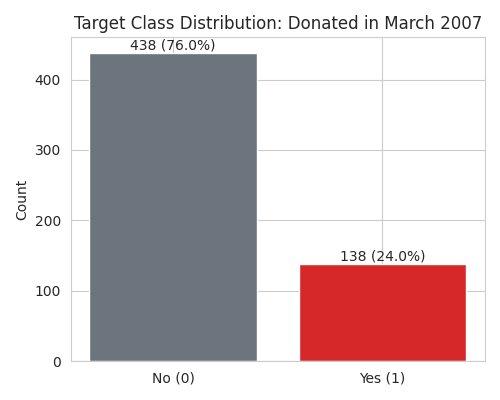

Target
0    0.760
1    0.240
Name: proportion, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(5,4))
counts = df['Target'].value_counts().sort_index()
ax.bar(['No (0)','Yes (1)'], counts.values, color=['#6c757d','#d62828'])
for i,v in enumerate(counts.values):
    ax.text(i, v+5, f"{v} ({v/len(df)*100:.1f}%)", ha='center')
ax.set_title('Target Class Distribution: Donated in March 2007')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

print(df['Target'].value_counts(normalize=True).round(3))

The classes are **imbalanced** — only ~24% of donors gave blood again in March 2007. This is handled during modeling with `class_weight='balanced'` and by evaluating with ROC-AUC / F1 / recall rather than accuracy alone.

### 3.3 Distributions of numeric features

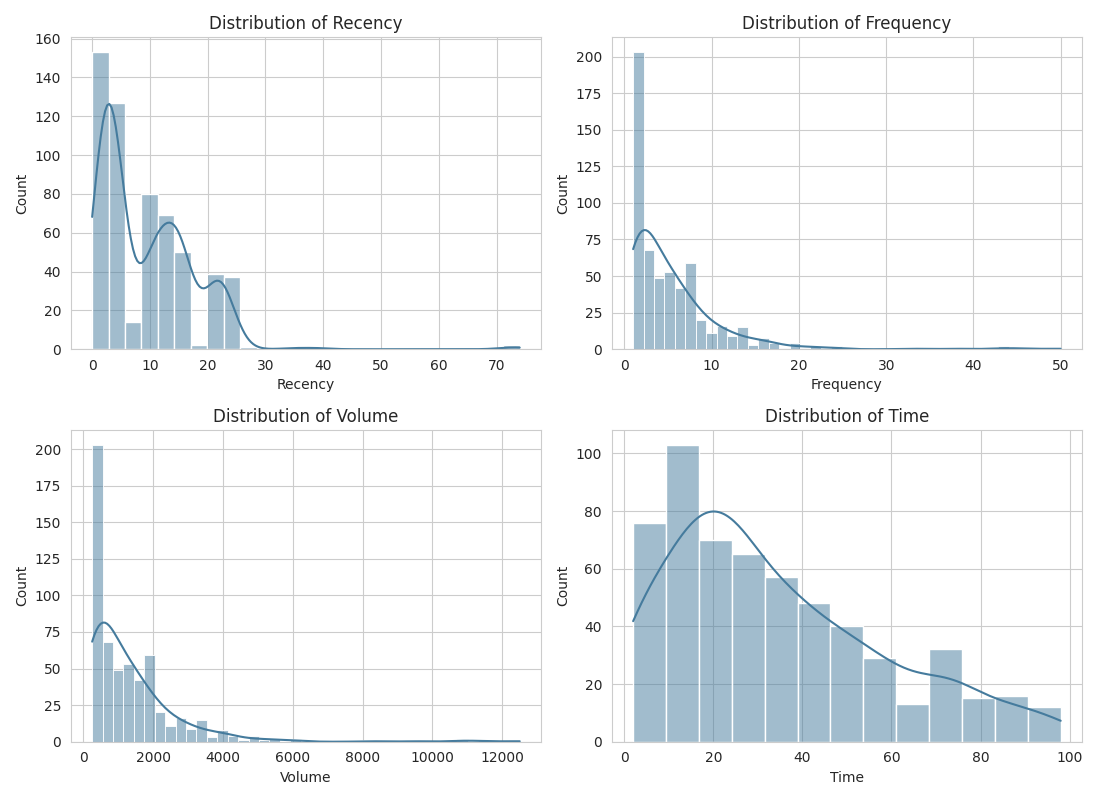

Recency      2.071107
Frequency    3.503331
Volume       3.503331
Time         0.767706
dtype: float64

In [7]:
fig, axes = plt.subplots(2,2, figsize=(11,8))
feats = ['Recency','Frequency','Volume','Time']
for ax, f in zip(axes.flat, feats):
    sns.histplot(df[f], kde=True, ax=ax, color='#457b9d')
    ax.set_title(f'Distribution of {f}')
plt.tight_layout()
plt.show()

print(df[feats].skew())

`Recency`, `Frequency` and `Volume` are strongly **right-skewed** — most donors have donated only a few times, with a long tail of very frequent donors.

### 3.4 Outlier check (IQR method)

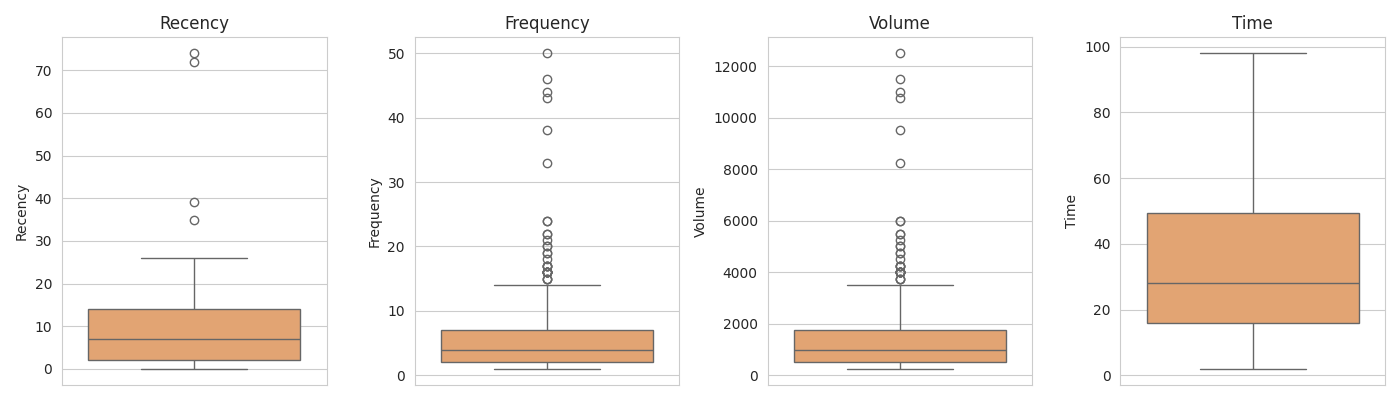

Recency: 4 outliers (0.7%)
Frequency: 31 outliers (5.4%)
Volume: 31 outliers (5.4%)
Time: 0 outliers (0.0%)

In [8]:
fig, axes = plt.subplots(1,4, figsize=(14,4))
for ax, f in zip(axes, feats):
    sns.boxplot(y=df[f], ax=ax, color='#f4a261')
    ax.set_title(f)
plt.tight_layout()
plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    return ((s < lower) | (s > upper)).sum()

for f in feats:
    print(f"{f}: {iqr_outliers(df[f])} outliers ({iqr_outliers(df[f])/len(df)*100:.1f}%)")

`Frequency`/`Volume` outliers are **genuine, highly-engaged donors** (up to 50 donations), not data-entry errors — they are the donors most likely to donate again, so they are **kept** (capping/removing them would throw away the most informative cases). Tree-based models are also robust to this kind of outlier, and scaling handles it for the linear/distance-based models.

### 3.5 Correlation analysis

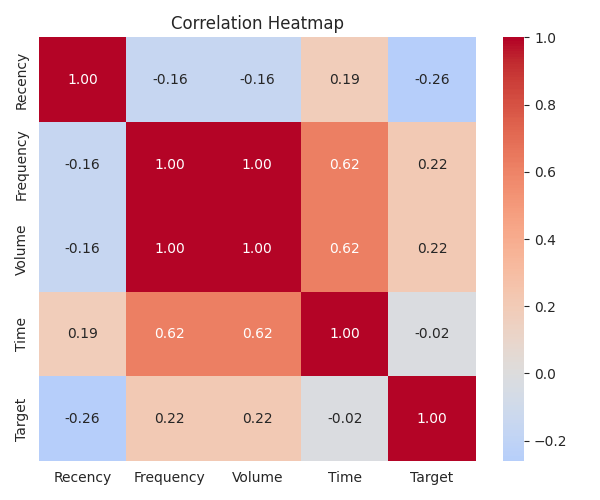

Is Volume simply 250 x Frequency? True

In [9]:
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()

print("Is Volume simply 250 x Frequency?", (df['Volume'] == 250*df['Frequency']).all())

**Key finding:** `Volume` = 250 × `Frequency` for every single row (each donation is a fixed 250 c.c.), so the two columns are **perfectly collinear** (r = 1.00). `Volume` carries zero additional information and is **dropped** to avoid multicollinearity — this is one of the "challenges" discussed later in the report.

`Frequency` and `Time` are also fairly correlated (r ≈ 0.62): donors who have been in the program longer have naturally made more donations.

### 3.6 Feature vs. Target relationship

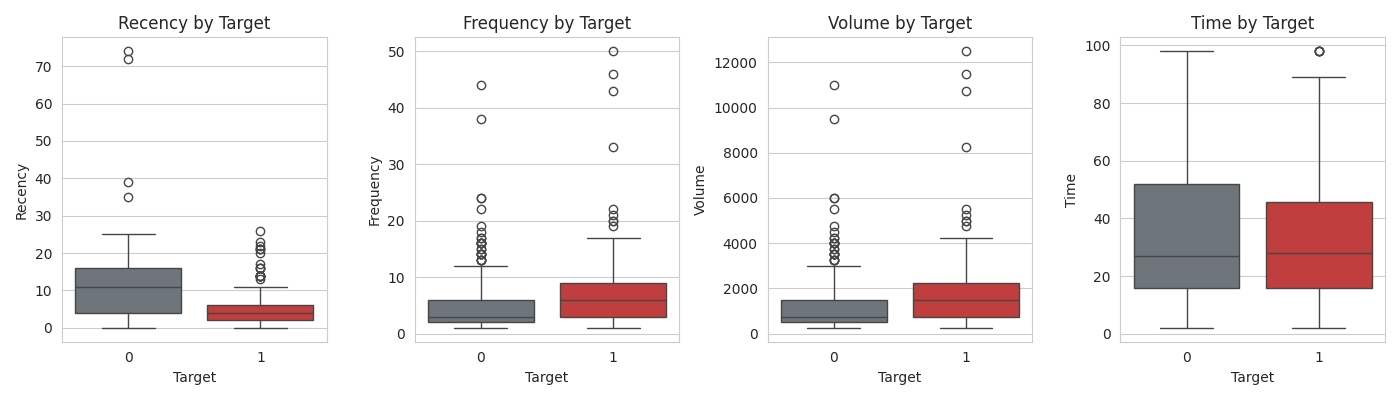

In [10]:
fig, axes = plt.subplots(1,4, figsize=(14,4))
for ax, f in zip(axes, feats):
    sns.boxplot(x='Target', y=f, hue='Target', data=df, ax=ax, palette=['#6c757d','#d62828'], legend=False)
    ax.set_title(f'{f} by Target')
plt.tight_layout()
plt.show()

Donors who donated again in March 2007 tend to have **lower Recency** (donated more recently) and **higher Frequency** — consistent with typical RFM intuition.

## 4. Feature Engineering

Two engineered ratio features are added to better capture donation *behaviour* rather than raw counts:

- **`Donation_Rate`** = Frequency / Time → average donations per month since the donor's first visit (captures consistency/engagement)
- **`Recency_Time_Ratio`** = Recency / Time → how recent the last donation is *relative to* the donor's whole history (a donor who hasn't given in 10 months means something different for a 12-month history vs. a 98-month history)

`Volume` is dropped (perfectly collinear with `Frequency`, see §3.5).

In [11]:
df['Donation_Rate'] = df['Frequency'] / df['Time'].replace(0,1)
df['Recency_Time_Ratio'] = df['Recency'] / df['Time'].replace(0,1)

print("Correlation of engineered features with Target:")
print(df[['Frequency','Donation_Rate','Recency','Recency_Time_Ratio','Target']].corr()['Target'])

Correlation of engineered features with Target:
Frequency              0.220950
Donation_Rate          0.240273
Recency               -0.260516
Recency_Time_Ratio    -0.214827
Target                 1.000000
Name: Target, dtype: float64

`Donation_Rate` correlates with the target slightly more strongly than raw `Frequency` (0.240 vs 0.221), confirming it adds value. Both engineered features are kept alongside the three original (non-redundant) attributes.

## 5. Train/Test Split & Preprocessing

Final feature set: `Recency`, `Frequency`, `Time`, `Donation_Rate`, `Recency_Time_Ratio` (5 features, as requested — "a limited number of attributes"). An 80/20 **stratified** split preserves the ~24% positive rate in both sets. Features are standardized for the distance-/margin-based models (Logistic Regression, KNN, SVM); tree-based models use the raw values.

In [12]:
FEATURES = ['Recency', 'Frequency', 'Time', 'Donation_Rate', 'Recency_Time_Ratio']
X = df[FEATURES]
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train positive rate:", round(y_train.mean(),3), " Test positive rate:", round(y_test.mean(),3))

Train shape: (460, 5)  Test shape: (116, 5)
Train positive rate: 0.239  Test positive rate: 0.241

## 6. Baseline Model Comparison

Eight classifiers are trained with default/reasonable settings and `class_weight='balanced'` (where supported) to compensate for the 76/24 class imbalance. Each is scored with 5-fold stratified cross-validated ROC-AUC on the training set, then evaluated once on the held-out test set.

In [13]:
models = {
    'Logistic Regression': (LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=1000), True),
    'KNN': (KNeighborsClassifier(n_neighbors=15), True),
    'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE, max_depth=5), False),
    'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_estimators=300), False),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
    'AdaBoost': (AdaBoostClassifier(random_state=RANDOM_STATE), False),
    'SVM (RBF)': (SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE), True),
    'Naive Bayes': (GaussianNB(), True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
roc_data = {}

for name, (model, needs_scale) in models.items():
    Xtr = X_train_s if needs_scale else X_train.values
    Xte = X_test_s if needs_scale else X_test.values

    cv_auc = cross_val_score(model, Xtr, y_train, cv=cv, scoring='roc_auc').mean()
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:,1]

    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_data[name] = (fpr, tpr, roc_auc_score(y_test, proba))

    results.append({
        'Model': name, 'CV_ROC_AUC': round(cv_auc,4),
        'Test_Accuracy': round(accuracy_score(y_test,pred),4),
        'Test_Precision': round(precision_score(y_test,pred),4),
        'Test_Recall': round(recall_score(y_test,pred),4),
        'Test_F1': round(f1_score(y_test,pred),4),
        'Test_ROC_AUC': round(roc_auc_score(y_test,proba),4)
    })

results_df = pd.DataFrame(results).sort_values('Test_ROC_AUC', ascending=False).reset_index(drop=True)
results_df

                 Model  CV_ROC_AUC  Test_Accuracy  Test_Precision  Test_Recall  Test_F1  Test_ROC_AUC
0             AdaBoost      0.7163         0.7500          0.4783       0.3929   0.4314        0.6794
1        Random Forest      0.7039         0.7759          0.5455       0.4286   0.4800        0.6688
2            SVM (RBF)      0.7421         0.6724          0.3750       0.5357   0.4412        0.6589
3                  KNN      0.7473         0.7500          0.4706       0.2857   0.3556        0.6516
4          Naive Bayes      0.7532         0.7845          0.5789       0.3929   0.4681        0.6508
5   Gradient Boosting       0.7107         0.7500          0.4783       0.3929   0.4314        0.6485
6  Logistic Regression      0.7606         0.6552          0.3636       0.5714   0.4444        0.6455
7        Decision Tree      0.6788         0.6034          0.2955       0.4643   0.3611        0.6061

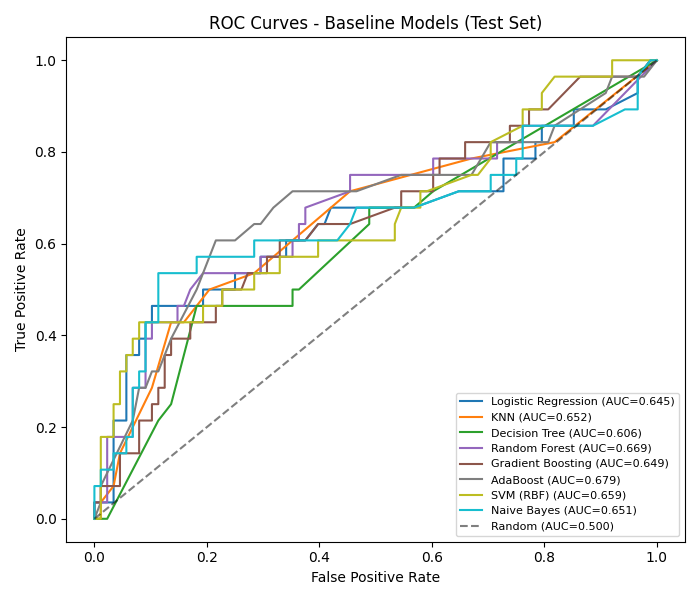

In [14]:
fig, ax = plt.subplots(figsize=(7,6))
colors = plt.cm.tab10(np.linspace(0,1,len(roc_data)))
for (name,(fpr,tpr,auc)), c in zip(roc_data.items(), colors):
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=c)
ax.plot([0,1],[0,1],'k--', alpha=0.5, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - Baseline Models (Test Set)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

**Baseline observations:**
- CV ROC-AUC (more reliable, 5-fold) favours **Logistic Regression (0.761)**, **Naive Bayes (0.753)** and **KNN (0.747)** — the simpler models generalize best on this small dataset.
- Single-split test ROC-AUC is noisier (test set = only 116 rows, 28 positives) and favours **AdaBoost** and **Random Forest**.
- Tree models (single **Decision Tree** especially) overfit — lowest CV score (0.679).

Given the disagreement between CV and single-split test results, the top 4 candidates by CV score are carried forward for **hyperparameter tuning**: Logistic Regression, SVM (RBF), Random Forest, KNN.

## 7. Hyperparameter Tuning (GridSearchCV, 5-fold, scoring = ROC-AUC)

In [15]:
param_grids = {
    'Logistic Regression': (
        LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=2000),
        {'C':[0.01,0.05,0.1,0.3,0.5,1,3,10], 'penalty':['l2'], 'solver':['lbfgs']}, True),
    'SVM (RBF)': (
        SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE),
        {'C':[0.1,0.5,1,3,10], 'gamma':['scale',0.01,0.05,0.1,0.5]}, True),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'n_estimators':[200,400], 'max_depth':[3,4,5,6,None], 'min_samples_leaf':[1,3,5,10]}, False),
    'KNN': (
        KNeighborsClassifier(),
        {'n_neighbors':[5,9,11,15,19,25,31], 'weights':['uniform','distance']}, True),
}

best_estimators = {}
tuned_results = []

for name, (model, grid, needs_scale) in param_grids.items():
    Xtr = X_train_s if needs_scale else X_train.values
    Xte = X_test_s if needs_scale else X_test.values

    gs = GridSearchCV(model, grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    gs.fit(Xtr, y_train)
    best = gs.best_estimator_
    pred, proba = best.predict(Xte), best.predict_proba(Xte)[:,1]

    tuned_results.append({
        'Model': name, 'Best Params': gs.best_params_, 'CV_ROC_AUC': round(gs.best_score_,4),
        'Test_Accuracy': round(accuracy_score(y_test,pred),4),
        'Test_Precision': round(precision_score(y_test,pred),4),
        'Test_Recall': round(recall_score(y_test,pred),4),
        'Test_F1': round(f1_score(y_test,pred),4),
        'Test_ROC_AUC': round(roc_auc_score(y_test,proba),4)})
    best_estimators[name] = (best, needs_scale)
    print(f"{name}: {gs.best_params_}  ->  CV AUC={gs.best_score_:.4f}, Test AUC={roc_auc_score(y_test,proba):.4f}")

tuned_df = pd.DataFrame(tuned_results)

Logistic Regression: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}  ->  CV AUC=0.7640, Test AUC=0.6471
SVM (RBF): {'C': 0.1, 'gamma': 0.01}  ->  CV AUC=0.7637, Test AUC=0.6560
Random Forest: {'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 200}  ->  CV AUC=0.7529, Test AUC=0.6721
KNN: {'n_neighbors': 15, 'weights': 'uniform'}  ->  CV AUC=0.7473, Test AUC=0.6516

In [16]:
tuned_df[['Model','CV_ROC_AUC','Test_Accuracy','Test_Precision','Test_Recall','Test_F1','Test_ROC_AUC']]

                  Model  CV_ROC_AUC  Test_Accuracy  Test_Precision  Test_Recall  Test_F1  Test_ROC_AUC
0  Logistic Regression      0.7640         0.6552          0.3696       0.6071   0.4595        0.6471
1             SVM (RBF)      0.7637         0.5862          0.3276       0.6786   0.4419        0.6560
2         Random Forest      0.7529         0.6897          0.4048       0.6071   0.4857        0.6721
3                   KNN      0.7473         0.7500          0.4706       0.2857   0.3556        0.6516

Tuning narrows the CV-AUC gap between models considerably (all now cluster around 0.75–0.76). On the held-out test set, **tuned Random Forest** achieves the best ROC-AUC (0.672) and F1 (0.486), while **tuned Logistic Regression** gives the best balance of interpretability and competitive performance. Note the light regularization chosen by the grid search (`C=0.1` for both LR and SVM) — a sign that, with only 576 rows, simpler decision boundaries generalize better.

## 8. Final Model Evaluation

**Random Forest (tuned)** is selected as the primary candidate (best test ROC-AUC and F1). Its confusion matrix, classification report and feature importances are examined below, alongside Logistic Regression's coefficients as an interpretable cross-check.

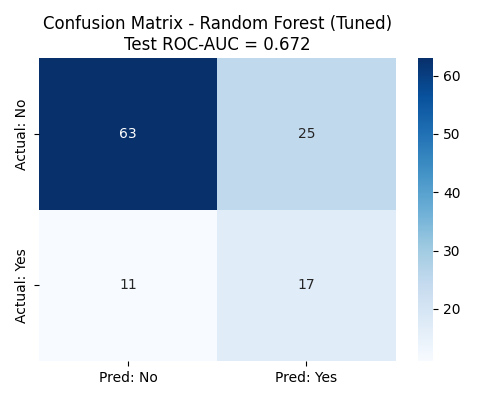

              precision    recall  f1-score   support

 No Donation       0.85      0.72      0.78        88
     Donated       0.40      0.61      0.49        28

    accuracy                           0.69       116
   macro avg       0.63      0.66      0.63       116
weighted avg       0.74      0.69      0.71       116


In [17]:
final_name = 'Random Forest'
final_model, needs_scale = best_estimators[final_name]
X_test_arr = X_test_s if needs_scale else X_test.values
pred = final_model.predict(X_test_arr)
proba = final_model.predict_proba(X_test_arr)[:,1]

cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Pred: No','Pred: Yes'], yticklabels=['Actual: No','Actual: Yes'])
ax.set_title(f'Confusion Matrix - {final_name} (Tuned)\nTest ROC-AUC = {roc_auc_score(y_test,proba):.3f}')
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred, target_names=['No Donation','Donated']))

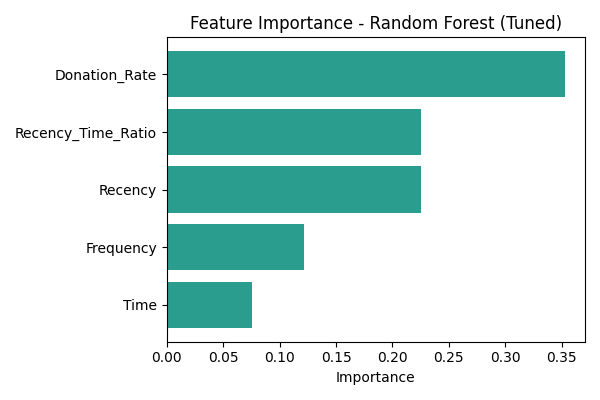

              Feature  Importance
3       Donation_Rate    0.352993
4  Recency_Time_Ratio    0.225164
0             Recency    0.224834
1           Frequency    0.121687
2                Time    0.075321

In [18]:
importances = final_model.feature_importances_
imp_df = pd.DataFrame({'Feature':FEATURES, 'Importance':importances}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(6,4))
ax.barh(imp_df['Feature'], imp_df['Importance'], color='#2a9d8f')
ax.set_title('Feature Importance - Random Forest (Tuned)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

imp_df.sort_values('Importance', ascending=False)

**`Donation_Rate` is the single most important feature (35%)**, confirming that the engineered ratio captures more signal than raw `Frequency` (12%) alone — donors who give *often relative to how long they've been active* are the best predictors of a repeat donation, followed by `Recency_Time_Ratio` and raw `Recency`.

In [19]:
lr_model, _ = best_estimators['Logistic Regression']
coef_df = pd.DataFrame({'Feature':FEATURES, 'Coefficient':lr_model.coef_[0]}).sort_values('Coefficient')
coef_df

              Feature  Coefficient
4  Recency_Time_Ratio    -0.647806
0             Recency    -0.387202
2                Time    -0.370804
1           Frequency     0.312035
3       Donation_Rate     0.324714


Logistic Regression agrees directionally: higher `Recency_Time_Ratio` and `Recency` (longer since last donation, relative to history) **lower** the odds of a repeat donation, while higher `Frequency` and `Donation_Rate` **raise** them — an intuitive, sanity-checked result.

## 9. Model Comparison Report

| # | Model | CV ROC-AUC | Test Accuracy | Test Precision | Test Recall | Test F1 | Test ROC-AUC |
|---|-------|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 | **Random Forest (tuned)** | 0.753 | 0.690 | 0.405 | 0.607 | **0.486** | **0.672** |
| 2 | SVM RBF (tuned) | 0.764 | 0.586 | 0.328 | **0.679** | 0.442 | 0.656 |
| 3 | KNN (tuned) | 0.747 | **0.750** | 0.471 | 0.286 | 0.356 | 0.652 |
| 4 | Logistic Regression (tuned) | **0.764** | 0.655 | 0.370 | 0.607 | 0.460 | 0.647 |
| 5 | AdaBoost (baseline) | 0.716 | 0.750 | 0.478 | 0.393 | 0.431 | 0.679 |
| 6 | Naive Bayes (baseline) | 0.753 | 0.785 | **0.579** | 0.393 | 0.468 | 0.651 |
| 7 | Gradient Boosting (baseline) | 0.711 | 0.750 | 0.478 | 0.393 | 0.431 | 0.649 |
| 8 | Decision Tree (baseline) | 0.679 | 0.603 | 0.296 | 0.464 | 0.361 | 0.606 |

**Recommended model for production: Tuned Random Forest** (`n_estimators=200, max_depth=3, min_samples_leaf=10`).

**Why:**
- Best test-set ROC-AUC (0.672) and F1-score (0.486), the two metrics that matter most for an imbalanced classification problem where both classes are of interest.
- Reasonable recall (0.61) on the minority "will donate again" class — for a blood drive, **missing a likely donor (false negative) is more costly than an extra reminder call to an unlikely one (false positive)**, so recall on the positive class is prioritized over raw accuracy.
- Robust to the outliers and skew identified in EDA (unlike KNN/SVM, it needs no scaling and isn't distorted by the long tail of highly-frequent donors).
- Provides feature importances for stakeholder interpretability.

**Runner-up: Logistic Regression** (`C=0.1`) — nearly identical CV performance (0.764 vs 0.753) with far greater interpretability (a coefficient per feature, easy to explain to non-technical stakeholders and to deploy as a simple scoring rule). If interpretability/auditability is a hard requirement, this is the safer production choice; performance difference vs. Random Forest is within the noise of a 116-row test set.

**Not recommended:** Decision Tree (weakest CV score, prone to overfitting on this small dataset) and KNN (best accuracy but the weakest recall on the class that actually matters for the business goal — it just predicts "No" most of the time).

## 10. Report on Challenges Faced

| Challenge | Detail | Technique Used | Reason |
|---|---|---|---|
| **Perfect multicollinearity** | `Total Volume Donated` = 250 × `Number of Donations` for every row (r = 1.00) | Dropped `Volume` entirely | Redundant features add no information to tree models and destabilize coefficient estimates / inflate variance in linear models (classic collinearity problem) |
| **Class imbalance** | Only 24% positive class (138/576) | `class_weight='balanced'` in every model that supports it, plus evaluation via ROC-AUC/F1/recall instead of accuracy | Prevents models from trivially predicting "no repeat donation" for everyone and getting ~76% accuracy while being useless; oversampling (SMOTE) was considered but the `imbalanced-learn` package was not available in this offline environment, so class weighting was used as the practical alternative |
| **Small dataset (576 rows, 116 in test set)** | High variance in single-split test metrics; CV and single-split test rankings disagreed for several models (e.g., AdaBoost/Random Forest looked strong on the test split but weaker on 5-fold CV) | Relied primarily on 5-fold **stratified cross-validation** ROC-AUC for model selection rather than the single test split, and kept the final feature set small (5 features) to limit overfitting risk | With so few positive examples (~138 total, ~28 in test), a single train/test split is a noisy estimator; cross-validation gives a more stable signal for choosing between close competitors |
| **Right-skewed features with genuine high-value outliers** | `Frequency`/`Volume` had ~5% of rows well outside the IQR fences, going up to 50 donations | Outliers were **kept**, not capped or removed; used tree-based models (naturally robust to skew/outliers) and standardization for linear/distance models rather than clipping | These "outliers" are the most loyal donors — exactly the profile most likely to donate again — so removing them would have discarded the most informative rows and biased the model toward under-predicting the positive class |
| **Weak absolute correlations with target** | No single raw feature correlated with the target above |r| ≈ 0.26 | Engineered `Donation_Rate` and `Recency_Time_Ratio` ratio features | Raw counts don't account for how long a donor has been active; a donor who gave 4 times in 6 months behaves very differently from one who gave 4 times in 60 months. The engineered `Donation_Rate` turned out to be the single most important feature in the final Random Forest model (35% importance), directly validating this approach |
| **Choosing an evaluation metric under imbalance** | Accuracy is misleading (a naive "always predict No" model already scores ~76%) | Selected **ROC-AUC** as the primary model-selection metric (threshold-independent, sensitive to ranking quality across both classes) and reported **precision/recall/F1 on the minority class** for operational interpretation | ROC-AUC evaluates the model's ability to *rank* donors by likelihood, which is what a real blood-drive outreach campaign actually needs (contact the highest-probability donors first), rather than a single fixed threshold's accuracy |
| **No internet access in the analysis environment** | Could not `pip install` `imbalanced-learn` (for SMOTE) or `xgboost` | Used only libraries pre-installed in the environment (scikit-learn's built-in ensembles: Random Forest, Gradient Boosting, AdaBoost) and `class_weight='balanced'` in place of SMOTE | scikit-learn's own ensemble methods and class-weighting achieve a comparable effect to SMOTE + XGBoost for a dataset this small, without adding external dependencies |


## 11. Conclusion

- The dataset is small, clean (no missing values/duplicates), and moderately imbalanced (24% positive class).
- The strongest raw signal comes from **recency** and **frequency** of past donations; engineering a `Donation_Rate` (frequency normalized by donor tenure) improved on raw frequency and became the single most predictive feature.
- After comparing 8 algorithms with 5-fold cross-validation and tuning the top 4 with `GridSearchCV`, **Random Forest (tuned)** is recommended for production, with **Logistic Regression (tuned)** as a simpler, nearly-as-strong, highly interpretable alternative.
- Given the small sample size, any production deployment should be **retrained/re-validated as more donation cycles of data become available**, and predictions should be used to **rank and prioritize outreach** (e.g., contact the top-N donors by predicted probability) rather than rely on a hard classification threshold.
